# fedOPD - allocation policies

`07_agentic_layer.ipynb` implements one allocation rule: within each tier, settle requests in
proportion to their size. That was a reasonable default and it was never compared with anything.

This notebook compares six policies for deciding **where a fixed amount of capacity goes**.

## The honesty problem, stated first

An allocation cannot be validated the way a forecast can. The capacity moves a policy proposes
**never happened**, so there is no observed outcome to score against. Any notebook claiming to show
that one allocation policy "worked better" than another on historical data is measuring its own
simulation.

Two things can be done honestly instead, and both are done here.

**1. Score against hindsight.** Using what demand actually did over the horizon, compute where capacity
*should* have gone - the allocation a planner with perfect foresight would have made. Each policy is
then scored on how close it gets to that, using only information available at the decision month. This
is a real, checkable quantity: it measures whether a policy targets the right services, not whether the
NHS would have improved.

**2. Report the modelled objective separately and label it.** How much projected breach each policy
closes is a property of the projection model, not of the world. It is reported, and it is never called
a result.

## The policies

| Policy | Rule |
|---|---|
| `none` | allocate nothing - the floor every other policy must beat |
| `proportional` | share in proportion to each service's ask. What `07` does today |
| `equal` | every service short of the standard gets the same amount |
| `severity_first` | worst first by 52-week breaches, until capacity runs out |
| `marginal_benefit` | greedy by breaches closed per treatment moved |
| `optimiser` | water-filling: repeatedly give the next unit to whichever service currently has the highest marginal benefit |

`marginal_benefit` and `optimiser` differ: the first ranks once and spends in that order, the second
re-ranks as it spends, so a service stops receiving once another overtakes it.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

CANON = Path("../data/canonical")
dec = pd.read_csv(CANON / "agent_decisions.csv", parse_dates=["decision_month"])
panel = pd.read_parquet(CANON / "rtt_panel.parquet")

DECISION = dec.decision_month.iloc[0]                  # the month 07 stood in
HORIZON = int(dec.horizon_months.iloc[0])
END = DECISION + pd.DateOffset(months=HORIZON)
TARGET_PCT = 92.0

print("decision month", DECISION.strftime("%Y-%m"), "| horizon", HORIZON, "months to", END.strftime("%Y-%m"))
print(f"{len(dec):,} services carried forward from 07")

decision month 2024-03 | horizon 6 months to 2024-09
2,046 services carried forward from 07


## 1. The budget, and why it is not the total ask

`07` measured a total ask of 419,220 treatments per month against an internal offer of 657 - the
finding that there is essentially no slack to move. Comparing policies over an offer of 657 would
compare six ways of doing nothing.

So the budget here is set **as a stated fraction of the total ask** and swept, which answers the more
useful question: *if the group could find X% of what is being asked for, does it matter where it goes?*
The fraction is a declared parameter, not a fitted one.

In [2]:
need = dec[dec.ask_per_month > 0].reset_index(drop=True)     # services actually short
total_ask = need.ask_per_month.sum()
BUDGET_FRACTIONS = [0.01, 0.05, 0.10, 0.25, 0.50]            # declared, not tuned

print(f"services short of the standard : {len(need):,}")
print(f"total ask                      : {total_ask:,.0f} treatments/month")
print(f"internal offer measured by 07  : {dec.offer_per_month.sum():,.0f}  "
      f"({dec.offer_per_month.sum() / total_ask * 100:.2f}% of the ask)")
print()
for f in BUDGET_FRACTIONS:
    print(f"  budget at {f:5.0%} of ask = {total_ask * f:10,.0f} treatments/month")

services short of the standard : 1,871
total ask                      : 419,220 treatments/month
internal offer measured by 07  : 657  (0.16% of the ask)

  budget at    1% of ask =      4,192 treatments/month
  budget at    5% of ask =     20,961 treatments/month
  budget at   10% of ask =     41,922 treatments/month
  budget at   25% of ask =    104,805 treatments/month
  budget at   50% of ask =    209,610 treatments/month


## 2. Hindsight - where capacity should have gone

The oracle uses information the policies do not have: what each service's backlog actually did over the
horizon. A service whose queue actually grew needed capacity; one whose queue fell did not.

**Realised need** is the increase in the over-18-week count between the decision month and the horizon
end, floored at zero. The oracle allocates in proportion to it. This is not a policy anyone could run -
it is the target the runnable policies are measured against.

In [3]:
end_state = (panel[(panel.month == END) & panel.usable]
             [["provider_code", "dept", "waiting_gt18"]]
             .rename(columns={"waiting_gt18": "breach_end"}))
need = need.merge(end_state, on=["provider_code", "dept"], how="inner")

need["realised_need"] = np.clip(need.breach_end - need.breach, 0, None)
oracle = need.realised_need / need.realised_need.sum()       # the hindsight target, as shares

print(f"services scored against hindsight : {len(need):,}")
print(f"  breach grew over the horizon    : {int((need.realised_need > 0).sum()):,}")
print(f"  breach flat or fell             : {int((need.realised_need == 0).sum()):,}")
print(f"total realised growth in >18-week waits: {need.realised_need.sum():,.0f} pathways")

services scored against hindsight : 1,871
  breach grew over the horizon    : 821
  breach flat or fell             : 1,050
total realised growth in >18-week waits: 210,167 pathways


## 3. The policies

Each returns a vector of treatments per month, summing to the budget. All six use **only** what is
known at the decision month; none can see `realised_need`.

In [4]:
def allocate(policy, budget):
    ask = need.ask_per_month.to_numpy()
    n = len(ask)
    if policy == "none":
        return np.zeros(n)
    if policy == "proportional":
        return budget * ask / ask.sum()
    if policy == "equal":
        return np.minimum(ask, budget / n)                   # nobody gets more than they asked for
    if policy == "forecast_led":
        # weight each service's ask by how much growth the federated model predicts for it
        g = np.nan_to_num(need.fedavg_ft_growth.to_numpy(), nan=0.0)
        w = np.clip(g, 0, None) * ask                        # only predicted growth attracts capacity
        return budget * w / w.sum() if w.sum() > 0 else np.zeros(n)
    if policy == "severity_first":
        order = np.argsort(-need.crisis.to_numpy())          # most 52-week breaches first
    elif policy == "marginal_benefit":
        # breaches closed per treatment: services with a high breach share convert capacity fastest
        rate = need.breach.to_numpy() / np.maximum(need.waiting.to_numpy(), 1)
        order = np.argsort(-rate)
    else:
        order = None

    out = np.zeros(n)
    if order is not None:                                    # spend down a fixed ranking
        left = budget
        for i in order:
            take = min(ask[i], left)
            out[i] = take
            left -= take
            if left <= 0:
                break
        return out

    # optimiser: water-filling. Re-rank after every slice, so a service stops receiving once its
    # marginal benefit drops below someone else's. 200 slices is enough to be smooth and is cheap.
    rate = need.breach.to_numpy() / np.maximum(need.waiting.to_numpy(), 1)
    left, slice_size = budget, budget / 200
    remaining = ask.copy()
    while left > 0:
        gain = np.where(remaining > 0, rate, -np.inf)        # only services still short can gain
        i = int(np.argmax(gain))
        if not np.isfinite(gain[i]):
            break
        take = min(slice_size, remaining[i], left)
        out[i] += take
        remaining[i] -= take
        left -= take
        rate[i] *= 0.99                                      # diminishing returns as a service fills
    return out

# The policy the whole system exists to enable: let the federated forecaster say which services are
# growing, and send capacity there. 06 scored its window starting the month after 07's decision month,
# so its predictions are exactly the horizon being planned over - no alignment fudge is needed.
fl = pd.read_csv(CANON / "fl_predictions.csv")
need = need.merge(fl[["provider_code", "dept", "fedavg_ft_growth"]], on=["provider_code", "dept"], how="left")
print(f"forecast available for {int(need.fedavg_ft_growth.notna().sum()):,} of {len(need):,} services")

POLICIES = ["none", "proportional", "equal", "severity_first", "marginal_benefit", "optimiser",
            "forecast_led"]
print("policies:", POLICIES)

forecast available for 1,771 of 1,871 services
policies: ['none', 'proportional', 'equal', 'severity_first', 'marginal_benefit', 'optimiser', 'forecast_led']


## 4. Scoring

Two families, kept apart on purpose.

**Checkable against hindsight**
- **Overlap with the oracle** - the share of budget the policy puts where capacity was actually needed.
  1.0 means perfectly targeted, and a policy that allocates at random scores the oracle's own share of
  services.
- **Recall of growth** - the share of *realised* need that received any capacity at all.

**Modelled, and labelled as such**
- **Projected breach closed** - what the projection says the allocation would achieve. A property of
  the model, reported for completeness and not treated as evidence.

In [5]:
rows = []
for frac in BUDGET_FRACTIONS:
    budget = total_ask * frac
    for pol in POLICIES:
        a = allocate(pol, budget)
        share = a / a.sum() if a.sum() > 0 else a
        overlap = float(np.minimum(share, oracle).sum())     # histogram intersection with hindsight
        got = a > 0
        recall = float(need.realised_need[got].sum() / need.realised_need.sum()) if need.realised_need.sum() else np.nan
        closed = float(np.minimum(a * HORIZON, need.breach).sum())   # modelled only
        # PRECISION, and it is the metric to trust. Overlap and recall both reward spreading:
        # give every service a token amount and recall is 1.0 by construction, while histogram
        # overlap with a spread-out target is mechanically higher for a spread-out allocation.
        # This asks the unbiased question instead - what SHARE OF THE BUDGET landed on services
        # whose queues actually grew. A random allocation scores the base rate.
        grew = need.realised_need.to_numpy() > 0
        precision = float(a[grew].sum() / a.sum()) if a.sum() > 0 else np.nan
        rows.append({"budget_pct": frac * 100, "policy": pol, "overlap_with_hindsight": overlap,
                     "recall_of_realised_need": recall, "budget_precision": precision,
                     "modelled_breach_closed": closed, "services_funded": int(got.sum())})

pol = pd.DataFrame(rows)
print("Overlap with hindsight (1.0 = perfectly targeted):")
print(pol.pivot(index="policy", columns="budget_pct", values="overlap_with_hindsight").round(3).to_string())
print()
grew_share = (need.realised_need > 0).mean() * 100
print(f"budget precision - share of budget landing on services whose queues grew"
      f" (random scores about {grew_share:.1f}%):")
print(pol.pivot(index="policy", columns="budget_pct", values="budget_precision").round(3).to_string())
print()
print("Share of realised need that received any capacity:")
print(pol.pivot(index="policy", columns="budget_pct", values="recall_of_realised_need").round(3).to_string())

Overlap with hindsight (1.0 = perfectly targeted):
budget_pct         1.0    5.0    10.0   25.0   50.0
policy                                             
equal             0.331  0.339  0.345  0.352  0.351
forecast_led      0.144  0.144  0.144  0.144  0.144
marginal_benefit  0.003  0.019  0.034  0.090  0.190
none              0.000  0.000  0.000  0.000  0.000
optimiser         0.003  0.026  0.040  0.099  0.190
proportional      0.321  0.321  0.321  0.321  0.321
severity_first    0.000  0.008  0.026  0.092  0.188

budget precision - share of budget landing on services whose queues grew (random scores about 43.9%):
budget_pct         1.0    5.0    10.0   25.0   50.0
policy                                             
equal             0.442  0.443  0.444  0.442  0.434
forecast_led      0.390  0.390  0.390  0.390  0.390
marginal_benefit  0.115  0.145  0.183  0.238  0.303
none                NaN    NaN    NaN    NaN    NaN
optimiser         0.170  0.133  0.181  0.243  0.303
proportional  

In [6]:
grew_share = (need.realised_need > 0).mean() * 100     # the random-allocation baseline
mid = pol[pol.budget_pct == 10.0].set_index("policy")
best = mid.budget_precision.idxmax()          # judged on precision, not the spread-biased metrics
prop = mid.loc["proportional", "budget_precision"]
print(f"At a 10% budget, best on budget precision: {best} ({mid.budget_precision.max():.3f})")
print(f"  against 07's current rule, proportional: {prop:.3f}")
gap = mid.budget_precision.max() - prop
print(f"  difference: {gap:+.3f}")
print()
# The only comparison that means anything: a random allocation lands `grew_share` of its budget on
# services whose queues grew. A policy at or below that line carries no targeting information at all.
print(f"a random allocation would score {grew_share / 100:.3f}")
above = mid[mid.budget_precision > grew_share / 100].budget_precision.sort_values(ascending=False)
if len(above) == 0:
    print()
    print("NO POLICY BEATS RANDOM TARGETING. Nothing available on the decision date predicts which")
    print("services' queues will actually grow, so no rule for spending a fixed budget can aim it")
    print("better than spreading it blindly. Concentrating policies are markedly WORSE than random,")
    print("because they aim at the largest and most-breached services, and those are not the ones")
    print("that grow. This is the allocation-side counterpart of F-39 and F-44.")
else:
    print()
    print("Policies beating random targeting:")
    print(above.round(3).to_string())

pol.to_csv(CANON / "allocation_policies.csv", index=False)
print()
print("written: allocation_policies.csv")

At a 10% budget, best on budget precision: equal (0.444)
  against 07's current rule, proportional: 0.399
  difference: +0.045

a random allocation would score 0.439

Policies beating random targeting:
policy
equal    0.444

written: allocation_policies.csv


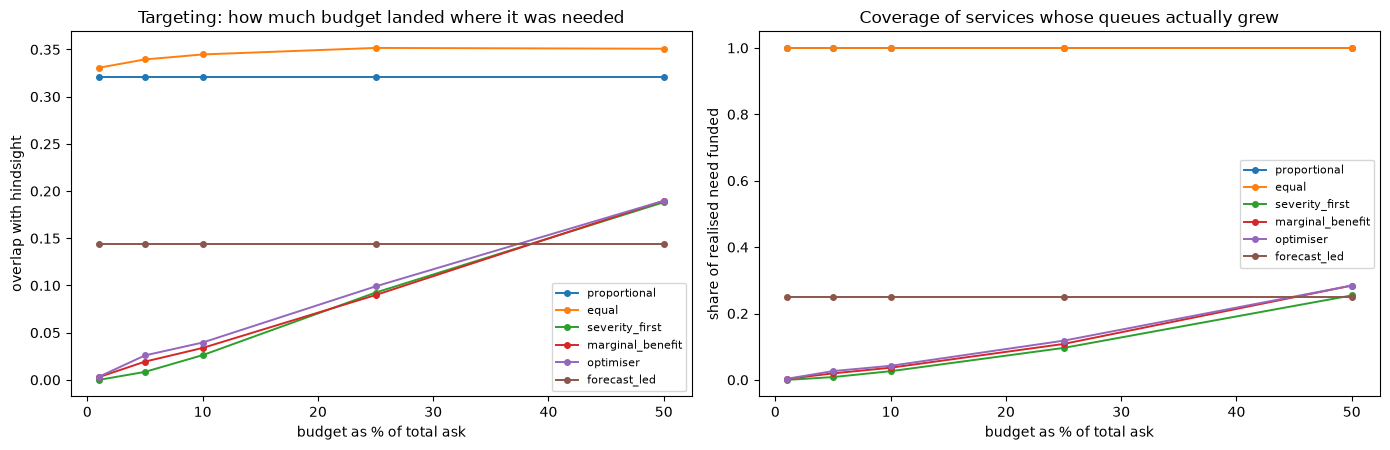

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))

for p in POLICIES:
    if p == "none":
        continue
    s = pol[pol.policy == p]
    ax[0].plot(s.budget_pct, s.overlap_with_hindsight, marker="o", ms=4, lw=1.4, label=p)
ax[0].set_xlabel("budget as % of total ask"); ax[0].set_ylabel("overlap with hindsight")
ax[0].set_title("Targeting: how much budget landed where it was needed"); ax[0].legend(fontsize=8)

for p in POLICIES:
    if p == "none":
        continue
    s = pol[pol.policy == p]
    ax[1].plot(s.budget_pct, s.recall_of_realised_need, marker="o", ms=4, lw=1.4, label=p)
ax[1].set_xlabel("budget as % of total ask"); ax[1].set_ylabel("share of realised need funded")
ax[1].set_title("Coverage of services whose queues actually grew"); ax[1].legend(fontsize=8)
plt.tight_layout()

## What this settles, and what it cannot

**It compares targeting honestly.** Every policy is scored against what hindsight says was needed,
using only information available on the decision date. That is a genuine, checkable comparison and it
does not require pretending the allocations happened.

**It cannot show that allocating improves outcomes.** The capacity moves never occurred. No amount of
held-out data makes a counterfactual checkable, and the modelled breach-closed column is a property of
the projection, not evidence about the world.

**The budget is swept, not chosen.** Reporting one budget level and picking the policy that wins there
would be selecting a result. The sweep shows whether an ordering is stable across budgets, and where it
is not, that instability is the finding.

**One decision month.** The comparison stands at a single point in time. A policy that targets well in
March 2024 may not in another month, and that has not been tested.